# ERC circularité · 04 · Modèle de Rex

**Question** : quand on extrait une pièce d'un FRU rebuté, quelle est la probabilité *q* qu'elle soit réutilisable ?

Tout le reste du choix entre réemploi et recyclage se mesure (valeur de la pièce, temps d'extraction et de test, prix au kilo). *q* est la seule grandeur qu'il faut estimer : le « modèle de Rex » est le modèle qui l'estime, par couple (type de FRU, pièce).

**Décision éclairée** : quelles pièces tester en priorité pendant l'audit de démontage, et quelle valeur de *q* transmettre au modèle de ligne (notebook 05).

**Comment il fonctionne** : il part d'un *a priori* tiré de la consommation, puis le corrige avec les résultats de l'audit de démontage (pièces testées, pièces bonnes). Plus l'audit avance, plus l'a priori s'efface. La formulation complète est dans [docs/Modele_mathematique.md](../docs/Modele_mathematique.md), section 8.

In [1]:
import sys
from pathlib import Path

# Le dossier est celui qui contient le code (erc/) : le parent de notebooks/.
dossier = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "erc" / "__init__.py").is_file()), Path.cwd().parent)
sys.path.insert(0, str(dossier))
import erc
from erc import affichage as aff

ctx = erc.executer(jusqua="rex")

ERC circularité — DÉMONSTRATION (données fictives)


  étape sources       3 artefacts → artefacts/00_sources/


  étape classement   13 artefacts → artefacts/01_classement/


  étape flux         14 artefacts → artefacts/02_flux/


  étape fiabilite    11 artefacts → artefacts/03_fiabilite/


  étape rex          13 artefacts → artefacts/04_rex/


In [2]:
aff.etat(ctx)

DÉMONSTRATION : toutes les données affichées sont fictives. Période : du 01/06/2026 au 01/11/2026, 154 jours extraits. Aucune anomalie de calcul.

## 1. L'a priori tiré de la consommation

Avant tout audit, la seule information est la consommation en réparation : une pièce souvent changée est souvent défectueuse.

- **p_défaut** = pièces consommées ÷ (réparations du FRU × pièces par FRU), corrigé de la part des remplacements faits par précaution ;
- **q0** = (1 − p_défaut), corrigé d'un facteur « FRU rebuté plus abîmé qu'un FRU réparé », de la casse au démontage et du rendement du test.

**Limites** : le nombre de pièces par FRU (`n_par_fru`) est inconnu avant un audit de démontage ; s'il n'est pas saisi, le calcul prend le maximum observé sur une réparation, qui n'est qu'un minimum, et le signale. Les correctifs non saisis prennent une valeur neutre, signalée dans la colonne « Correctifs ». L'a priori est donc une hypothèse de départ, pas une mesure.

In [3]:
aff.table(ctx, "rex", "A priori (consommation)")

Type de FRU,Pièce,Pièces consommées,Réparations du FRU,n_par_fru,Source n_par_fru,p_défaut,Correctifs,q0
FRU-A100-R,P-1004,86,249,1,saisi,"0,345",neutres : part préventive,"0,471"
FRU-A100-R,P-1005,31,249,1,saisi,"0,124",neutres : part préventive,"0,717"
FRU-A100-R,P-1001,200,249,2,saisi,"0,241",tous saisis,"0,587"
FRU-A100-R,P-1002,170,249,2,saisi,"0,205",tous saisis,"0,627"
FRU-A100-R,P-1006,119,249,3,saisi,"0,159",neutres : part préventive,"0,678"
FRU-A100-R,P-1007,55,249,2,saisi,"0,110",neutres : part préventive,"0,732"
FRU-A100-R,P-1003,277,249,4,saisi,"0,278",neutres : part préventive,"0,546"
FRU-A200-R,P-2001,52,110,1,saisi,"0,473",neutres : part préventive,"0,330"
FRU-A200-R,P-1002,74,110,2,saisi,"0,202",tous saisis,"0,631"
FRU-A200-R,P-2002,76,110,2,saisi,"0,345",neutres : part préventive,"0,471"


## 2. L'audit de démontage

Les données qui entraînent le modèle : pour chaque lot audité, le type de FRU, la pièce, le nombre de pièces testées et le nombre de pièces bonnes. Fichier attendu : `Acquisition/audit_demontage.csv` (colonnes `Date;Type de FRU;Pièce;Pièces testées;Pièces bonnes`).

**Limite** : sans ce fichier, la suite du notebook ne montre que l'a priori.

In [4]:
aff.table(ctx, "rex", "Audit de démontage", n=10)

Date,Type de FRU,Pièce,Pièces testées,Pièces bonnes
21/09/2026,FRU-A100-R,P-1001,4,1
21/09/2026,FRU-A100-R,P-1003,6,1
21/09/2026,FRU-A100-R,P-1004,10,1
21/09/2026,FRU-B300-R,P-3001,4,3
21/09/2026,FRU-B300-R,P-3002,10,5
28/09/2026,FRU-A100-R,P-1001,8,3
28/09/2026,FRU-A100-R,P-1003,7,2
28/09/2026,FRU-A100-R,P-1004,10,4
28/09/2026,FRU-B300-R,P-3001,10,3
28/09/2026,FRU-B300-R,P-3002,4,3


## 3. La probabilité de réemploi après l'audit

Pour chaque couple (type de FRU, pièce) : la valeur de *q* retenue, son intervalle à 90 %, l'a priori de départ et le nombre de pièces testées.

**Lecture** : quand l'audit a porté sur la pièce, le point bleu s'écarte du losange (l'a priori) et l'intervalle se resserre. Quand aucune pièce n'a été testée, la valeur n'est que l'a priori et son intervalle est large : ce sont les pièces à tester en priorité si leur valeur est élevée.

**Limite** : *q* est une moyenne par type de FRU et par pièce. Il ne tient pas compte de l'âge du FRU ni du motif de rebut.

**Probabilité de réemploi.** Pour chaque couple (type de FRU, pièce) : la probabilité q qu'une pièce extraite soit réutilisable, avec son intervalle à 90 %, l'a priori tiré de la consommation (losange) et le nombre de pièces testées. C'est la valeur transmise au modèle de ligne.

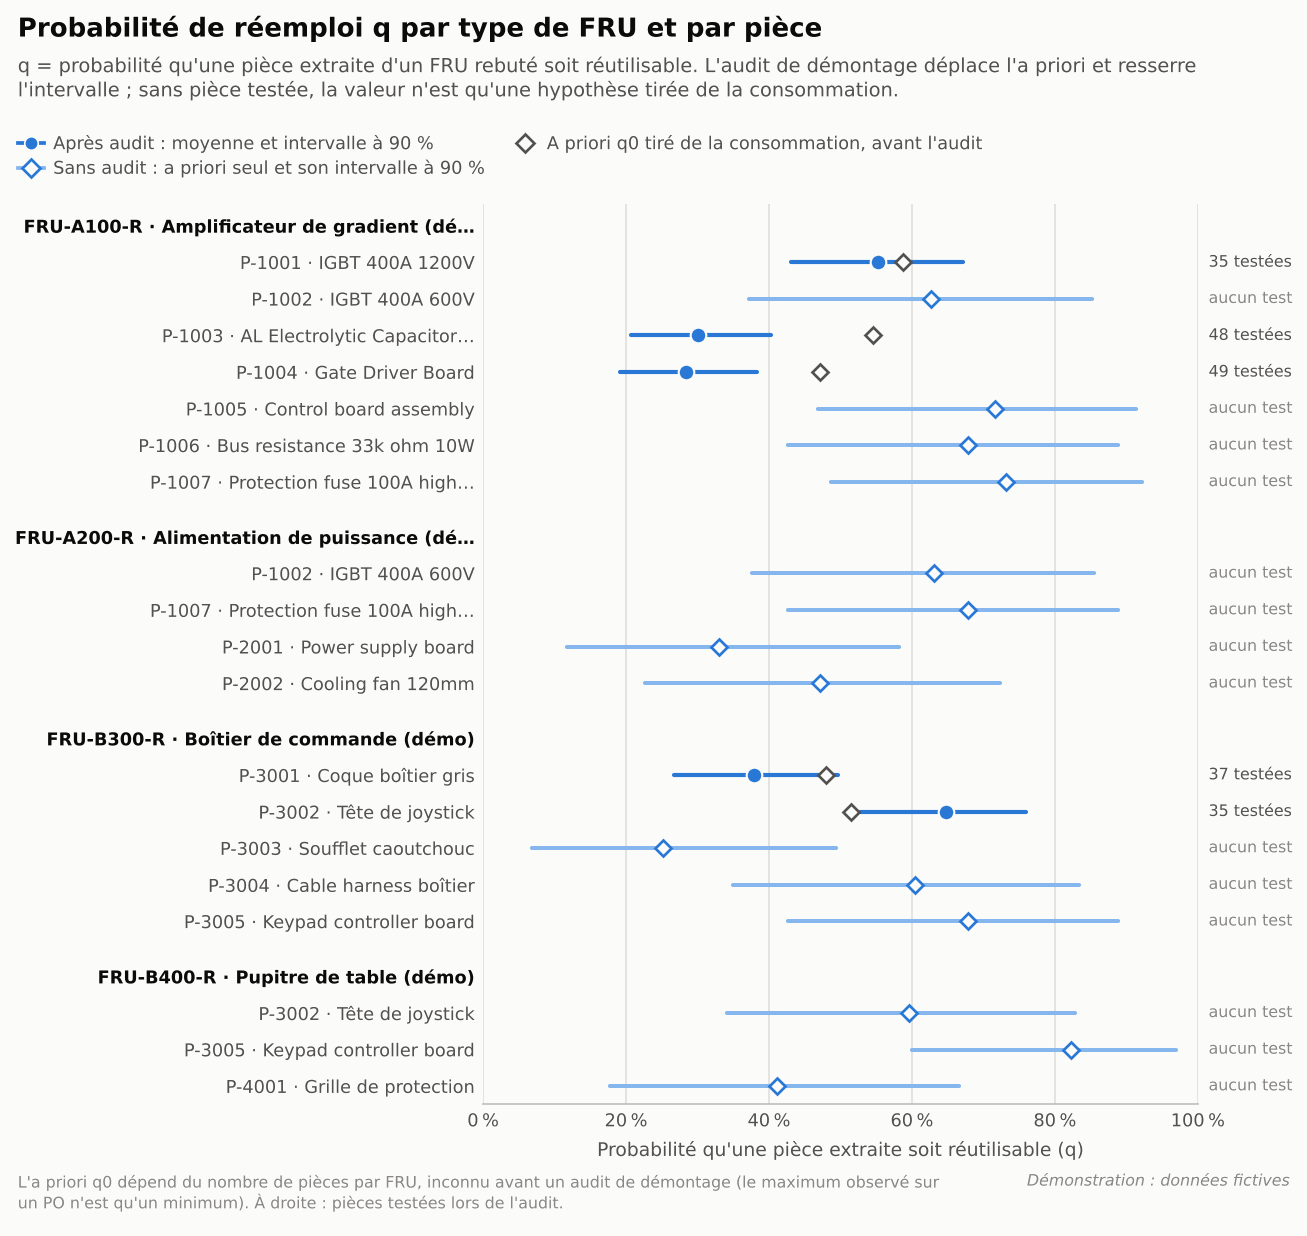

In [5]:
aff.figures(ctx, "rex", "Probabilité de réemploi")

In [6]:
aff.table(ctx, "rex", "A posteriori", colonnes=["Type de FRU", "Pièce", "q0", "Pièces testées", "Pièces bonnes", "q moyen", "q bas (5 %)", "q haut (95 %)",
          "Poids des données", "Transmis au modèle de ligne"])

Type de FRU,Pièce,q0,Pièces testées,Pièces bonnes,q moyen,q bas (5 %),q haut (95 %),Poids des données,Transmis au modèle de ligne
FRU-A100-R,P-1001,"0,587",35,19,"0,553","0,431","0,672","77,8 %",oui
FRU-A100-R,P-1002,"0,627",0,0,"0,627","0,373","0,852","0,0 %",oui
FRU-A100-R,P-1003,"0,546",48,12,"0,301","0,207","0,403","82,8 %",oui
FRU-A100-R,P-1004,"0,471",49,12,"0,283","0,192","0,383","83,1 %",oui
FRU-A100-R,P-1005,"0,717",0,0,"0,717","0,469","0,913","0,0 %",oui
FRU-A100-R,P-1006,"0,678",0,0,"0,678","0,426","0,888","0,0 %",oui
FRU-A100-R,P-1007,"0,732",0,0,"0,732","0,487","0,922","0,0 %",oui
FRU-A200-R,P-1002,"0,631",0,0,"0,631","0,376","0,854","0,0 %",oui
FRU-A200-R,P-1007,"0,678",0,0,"0,678","0,426","0,888","0,0 %",oui
FRU-A200-R,P-2001,"0,330",0,0,"0,330","0,117","0,582","0,0 %",oui


## 4. Le modèle prédit-il bien ?

Chaque lot de l'audit est d'abord prédit avec ce que le modèle savait avant, puis sert à le mettre à jour : aucune donnée ne sert à la fois à apprendre et à noter. Le modèle retenu (Bêta-binomial) est comparé à deux références simples : l'a priori seul, jamais mis à jour, et la fréquence observée, sans a priori.

**Lecture** : Brier, log-perte et écart absolu moyen doivent être les plus bas possible ; la couverture de l'intervalle à 90 % doit être proche de 90 %. Si une référence simple fait aussi bien ou mieux que le modèle retenu, c'est que l'a priori n'apporte rien sur ces données : le dire, et revoir sa force (section suivante).

**Limite** : avec quelques dizaines de lots, les écarts entre modèles sont fragiles.

**Métriques par modèle.** Quatre mesures de la qualité de prédiction, pour le modèle retenu et ses deux références. Lecture : sur les trois premières, la barre la plus courte gagne ; la couverture doit être proche de 90 %. Si une référence fait mieux, l'a priori n'apporte rien sur ces données.

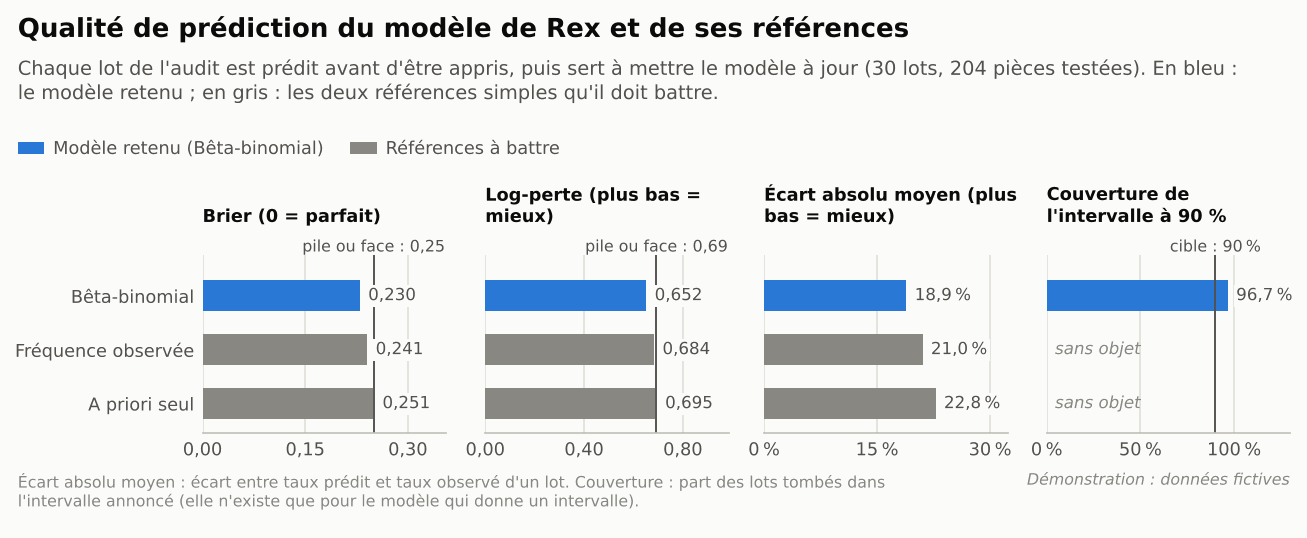

In [7]:
aff.figures(ctx, "rex", "Métriques par modèle")

In [8]:
aff.table(ctx, "rex", "Métriques")

Modèle,Lots,Pièces,Brier,Log-perte,Écart absolu moyen,Couverture IC90
Bêta-binomial,30,204,"0,230","0,652","18,9 %","96,7 %"
Fréquence observée,30,204,"0,241","0,684","21,0 %",
A priori seul,30,204,"0,251","0,695","22,8 %",


### Force de l'a priori (N0)

N0 dit combien de pièces testées « pèse » l'a priori. La table montre la qualité de prédiction pour plusieurs valeurs de N0 ; la figure marque la valeur utilisée par le modèle.

**Lecture** : si la valeur utilisée n'est pas celle qui donne la meilleure prédiction, la note sous la figure le dit. C'est un réglage à revoir quand l'audit réel sera disponible, pas avant.

**Réglage de N0.** Effet de la force de l'a priori N0 sur la qualité de prédiction. Lecture : l'axe vertical de la log-perte ne part pas de zéro, les écarts entre valeurs de N0 sont faibles ; la couverture doit rester proche de 90 %.

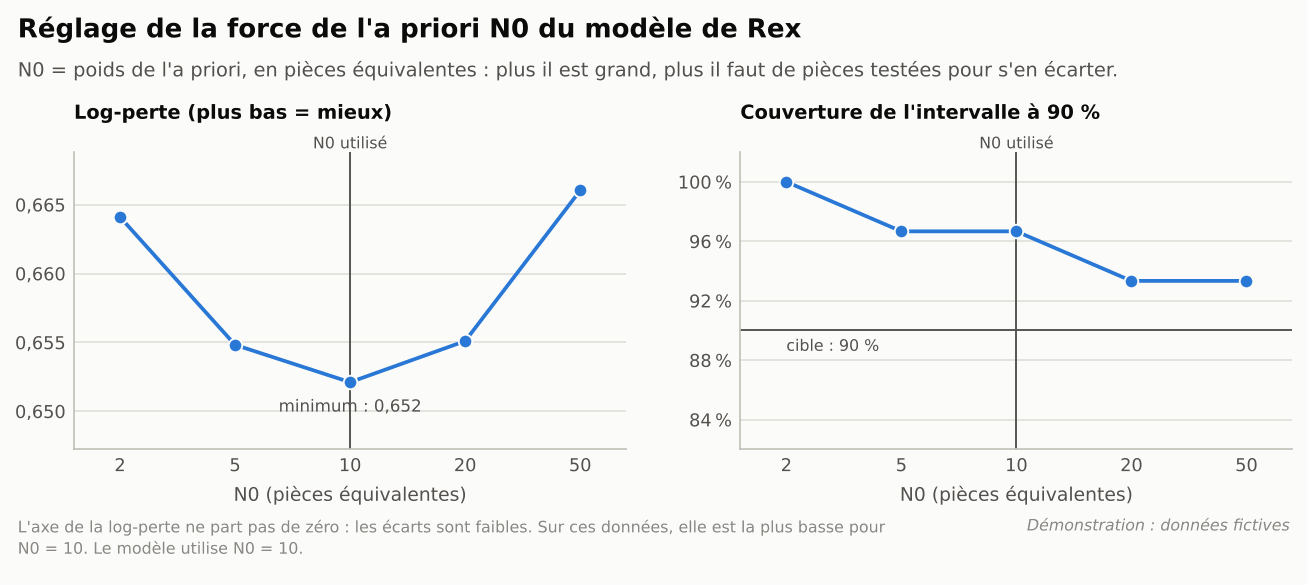

In [9]:
aff.figures(ctx, "rex", "Réglage de N0")

In [10]:
aff.table(ctx, "rex", "Réglage de N0")

N0,Log-perte,Brier,Couverture IC90
2,"0,664","0,235","100,0 %"
5,"0,655","0,231","96,7 %"
10,"0,652","0,230","96,7 %"
20,"0,655","0,231","93,3 %"
50,"0,666","0,237","93,3 %"


## 5. Banc d'essai synthétique des règles de décision

**Simulation, pas des données de l'atelier.** Le banc d'essai fabrique une pièce dont la vraie proportion de pièces bonnes est connue du simulateur, donne au modèle un a priori trop pessimiste, et compare trois règles de décision :

- **A priori seul** : décide une fois pour toutes sur l'a priori ;
- **Glouton** : suit la moyenne estimée ;
- **Thompson** : tire une valeur plausible de *q* à chaque pièce, ce qui conduit à tester de temps en temps une pièce jugée mauvaise.

**Lecture** : le regret est le gain perdu par rapport à une règle qui connaîtrait la vraie proportion. On n'apprend l'état d'une pièce que si on la teste : une règle qui ne teste jamais une pièce jugée mauvaise ne corrige jamais son erreur.

**Limite** : le banc d'essai démontre la méthode sur un cas construit. Il ne dit rien des pièces de l'atelier.

**Banc d'essai (regret).** Banc d'essai SYNTHÉTIQUE du choix réemploi ou recyclage : regret cumulé de 3 règles de décision quand l'a priori est trop pessimiste. Lecture : une courbe qui s'aplatit a appris ; une droite qui monte répète la même erreur à chaque pièce.

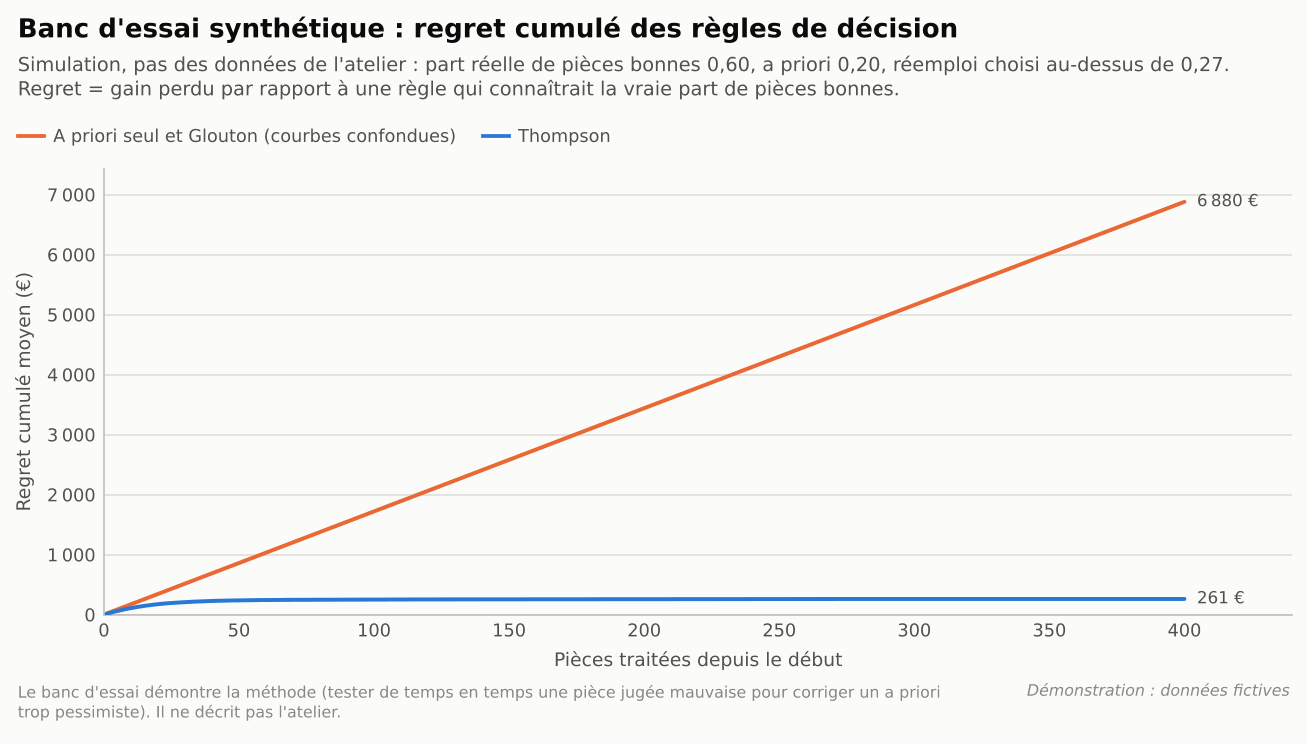

In [11]:
aff.figures(ctx, "rex", "Banc d'essai (regret)")

In [12]:
aff.table(ctx, "rex", "Banc d'essai des politiques")

Politique,Regret cumulé moyen (€),Regret par pièce (€),Part de pièces testées,q estimé final
A priori seul,6 880,"17,20","0,0 %","0,200"
Glouton,6 880,"17,20","0,0 %","0,200"
Thompson,261,"0,65","96,2 %","0,590"


## Notes de l'étape

Nombre de lots et de pièces de l'audit, force de l'a priori, paramètres du banc d'essai synthétique.

In [13]:
aff.notes(ctx, "rex")

Élément,Valeur
Lots d'audit,30
Pièces testées,204
"N0 (force de l'a priori, en pièces)",10
Banc d'essai › q vrai,"0,6"
Banc d'essai › q0,"0,2"
Banc d'essai › Seuil q* (réemploi si q > q*),"0,269"
Banc d'essai › Gain oracle par pièce (€),"19,2"
Banc d'essai synthétique,oui


---
Notebook suivant : **05_Ligne_demontage_tri**. Tous les fichiers affichés ici sont dans le dossier des artefacts, étape `04_rex` ; un classeur Excel du même nom réunit les tables de l'étape.